# 07. What the free air does to GloGEM

**For modellers who drive a glacier model with ERA5.** GloGEM normally takes the air temperature of a
glacier band from ERA5's 2 m temperature at the climate grid point, carried up or down to the band with a
monthly lapse rate. In the Alps that air is 4–6 °C too cold in winter at high stations. ERA5's own
*free air*, its temperature on pressure levels read at the band's height, matches the same stations within
about 0.5 °C in every month (chapter 13 of the development history).

GloGEM can now use the free air as an **option** (`air_temperature = 'freeair'`; the default stays the 2 m
air). This notebook shows, step by step, what that changes:

1. **The air:** where and when the band air moves (this part, no model runs).
2. **The air alone:** the mass balance with the free air and today's calibrated parameters.
3. **The calibration:** how T_off, the precipitation factor and the degree-day factors move.
4. **The result:** balance with height, seasonal balances against GLAMOS, sensitivity to warming.
5. **The future:** Alpine ice volume to 2100 (if the projections are run).
6. **Ice temperature:** what the new mass balance does to the thermal model's parameters.

Parts 2–6 are filled as the steps of the plan land
(`development_history/plans/2026-10-28_freeair_mass_balance_plan.md`). The figures are drawn by
`scripts/icetemp_analysis/freeair/freeair_mb_figs.py`, which the book's chapter 15 uses too. Nothing here
writes to disk.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'scripts' / 'icetemp_analysis' / 'freeair'))
import freeair_mb_figs as F
%matplotlib inline

## 1. The air

### 1.1 Which air is right?

The model's air against measured monthly means: 7 stations above 2800 m (Capanna Margherita,
Aiguille du Midi, Jungfraujoch, Plateau Rosa, Corvatsch, Gornergrat, Passo del Moro), and 6 valley stations
that lie 400–1140 m below ERA5's smooth ground (Samedan, Zermatt, Davos, Ulrichen, Chamonix, Sion).

- **High up, the free air is right all year;** today's air is 4–6 °C too cold from November to February.
- **In the valleys in winter it is the other way round:** cold air pools there, and the free air (ERA5's
  extrapolation below its own ground) is 2–6 °C too warm. Today's air is closer.

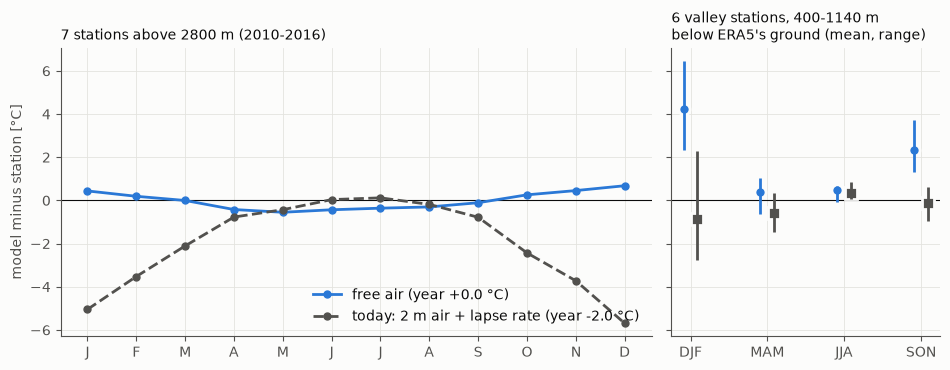

In [2]:
F.air_at_stations();

### 1.2 Is the lapse rate the problem?

No. The free air's own rate of cooling with height is close to the fixed monthly lapse rate GloGEM uses
(within about 0.05–0.1 °C per 100 m). What differs is the **starting point**: in winter ERA5's 2 m air sits
in a cold layer over its smooth, snowy model ground (~1900–2400 m in the Alps), and the lapse rate carries
that cold layer up to every band.

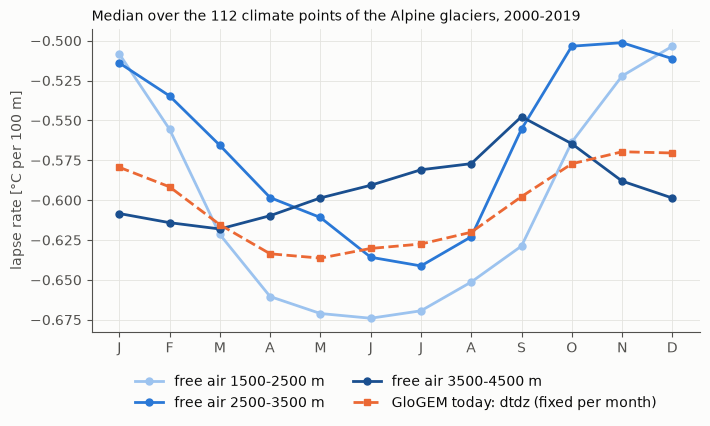

In [3]:
F.lapse_rates();

### 1.3 Where and when the band air moves

Free air minus today's band air (without T_off, which is the same in both), for every band of the 4079
Alpine glaciers, averaged over the calibration window (hydrological years 2000–2019).

- **Winter:** 5–6 °C warmer from December to January, at every height.
- **Summer:** 0.5–1 °C colder in June and July between 2500 and 4000 m.
- **For the mass balance this means:** slightly *less* melt in summer, and more rain instead of snow in
  autumn and spring. The calibration will have to make up for the summer part.

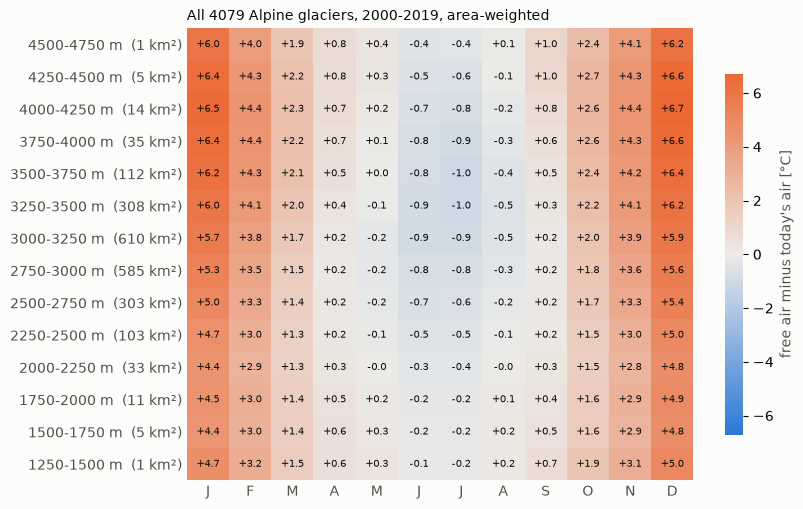

In [4]:
F.air_change();

### 1.4 How much ice lies below ERA5's ground?

Where a band lies below the grid cell's ground, the free air is ERA5's extrapolation, the case that fails at
the valley stations. Only 1.8 % of the Alpine glacier area lies there, and two-thirds of that is within
200 m of the ground, shallower than any of the valley stations. Step 2 of the plan chooses how to treat it.

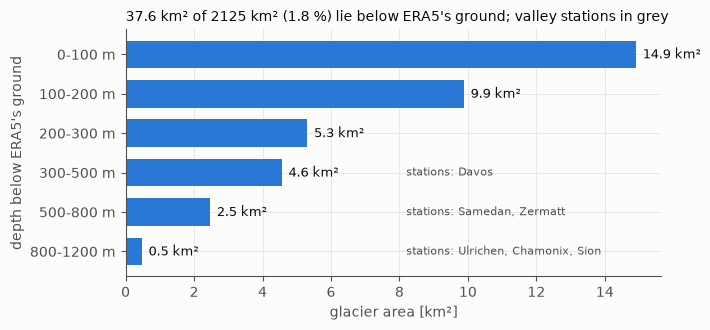

In [5]:
F.area_below_ground();

## 2. The air alone

*Filled after Step 3's first run: a past run with the free air and today's parameters.*

## 3. The calibration

*Filled after Step 3.*

## 4. The result

*Filled after Steps 3 and 4.*

## 5. The future

*Filled if Step 5 runs.*

## 6. Ice temperature

*Filled after Step 6.*

## Glossary

| term | meaning |
|---|---|
| free air | ERA5's temperature on pressure levels, read at the band's height |
| 2 m air | ERA5's air 2 m above its smooth model ground, carried to the band with a lapse rate |
| ERA5's ground | the smooth terrain height of the ERA5 grid cell (~1900–2400 m in the Alps) |
| lapse rate (`dtdz`) | how fast air cools with height; GloGEM uses one fixed value per calendar month |
| cold pool | cold air collecting in valleys in winter, below ERA5's ground |
| band | a 10 m elevation band of a glacier, GloGEM's unit of computation |
| T_off | the per-glacier temperature offset from the mass-balance calibration |
| hydrological year | October to September, named after the year it ends |
| GLAMOS | the Swiss glacier monitoring network |